# Example UKF


#### Import the proper classes and functions

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec



from geopack import geopack, t96
from noise_sim import NoiseSim
from orbit import Orbit
from orbit import Constants
from TD_noise_sim import TDNoiseSim

from ukf import UKF 
from ukf import rv_to_q
from ukf import q_mult
from ukf import q_to_R

Load IGRF coefficients ...


### 1) Basic Simulation (Oscillatory, Pure Gaussian Noise)

--- UKF Results ---

  Gaussian std: 2.0 nT

  True  B_orbit (last step): [-26.    18.32   1.21]
  Est.  B_orbit (last step): [-4.72 30.21  1.93]

  True  B_body  (last step): [-0.46 30.68 -8.47]
  Est.  B_body  (last step): [-0.15 29.05 -9.75]


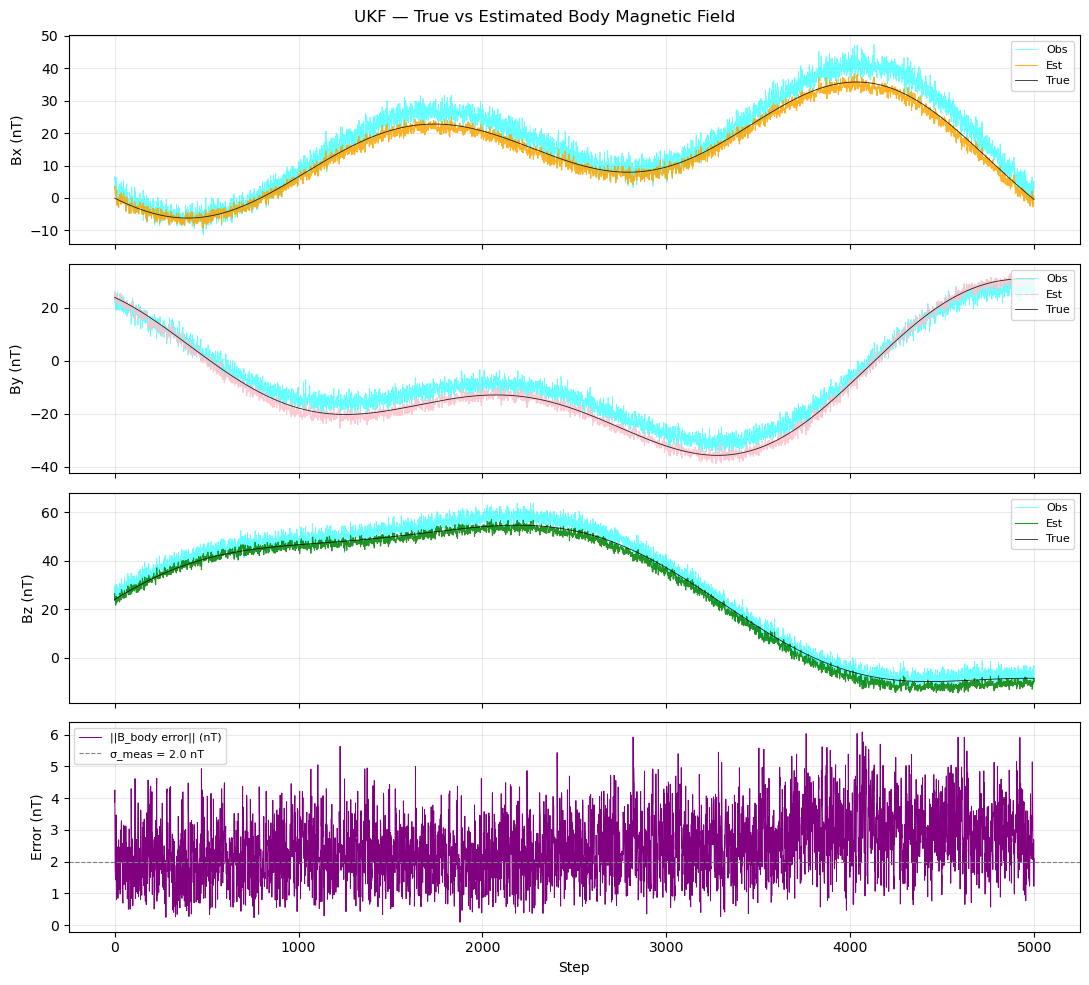

In [6]:
np.random.seed(0)

# known scaling matrix
true_D_cal = np.array([
    [1.15, 0.05, 0.02],
    [0.05, 0.90, 0.04],
    [0.02, 0.04, 1.05],
])

# known bias vector
true_b_cal = np.array([0.5, -0.3, 0.8])   # measured in nT

# attitude dynamics
true_w = np.array([0.001, -0.0005, 0.002])  # rad/step
true_q = np.array([1.0, 0.0, 0.0, 0.0])

N = 5000 # num steps
sigma_meas = 2.0  # measured in nT

ukf = UKF(
    D_cal=true_D_cal,
    b_cal=true_b_cal,
    sigma_meas=sigma_meas,
    sigma_att_walk=2e-3,   # ~0.1 deg/step
    sigma_B_walk=1.5,      # 1.5 nT/step
    sigma_b_walk=0.01,
)

# assume that true_q is known at the beginning
# give initial guess for state
ukf.q = true_q.copy()
ukf.x[3:6] = np.array([0.0, 0.0, 50.0])
ukf.P[0:3, 0:3] = np.eye(3) * 0.01  

B_true_hist = np.zeros((N, 3))
B_est_hist  = np.zeros((N, 3))
z = np.zeros((N, 3)) # measurement
err_body    = np.zeros(N)

for k in range(N):
    # calculate true attitude integration
    dq_true = rv_to_q(true_w)
    true_q  = q_mult(true_q, dq_true)
    true_q /= np.linalg.norm(true_q)

    # make basic, oscillatory magnetic field
    t = k / 6000 * 2 * np.pi
    true_B = np.array([
        30.0 * np.sin(t),
        25.0 * np.cos(t + 0.3),
        50.0 * np.sin(t * 0.5 + 0.5),
    ])

    # True undistorted body field
    true_B_body = q_to_R(true_q) @ true_B

    # measured magnetic field (+ noise)
    z[k] = true_D_cal @ (true_B_body) + true_b_cal \
        + np.random.normal(0, sigma_meas, 3)

    ukf.predict()
    est_B_body = ukf.update(z_meas=z[k])

    B_true_hist[k] = true_B_body
    B_est_hist[k]  = est_B_body
    err_body[k]    = np.linalg.norm(est_B_body - true_B_body)

print("--- UKF Results ---")
print(f"\n  Gaussian std: {sigma_meas:.1f} nT")
print(f"\n  True  B_orbit (last step): {np.round(true_B, 2)}")
print(f"  Est.  B_orbit (last step): {np.round(ukf.B_orbit_est, 2)}")
print(f"\n  True  B_body  (last step): {np.round(true_B_body, 2)}")
print(f"  Est.  B_body  (last step): {np.round(est_B_body, 2)}")

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
labels = ['Bx', 'By', 'Bz']
colors = ['orange', 'pink', 'green']
for i, (ax, lbl, col) in enumerate(zip(axes[:3], labels, colors)):
    ax.plot(z[:, i], color='cyan', lw=0.6, alpha=0.6, label='Obs')
    ax.plot(B_est_hist[:, i],  color=col, lw=0.8, alpha=0.85, label='Est')
    ax.plot(B_true_hist[:, i], color='k', lw=0.6, alpha=0.85, label='True')
    ax.set_ylabel(f'{lbl} (nT)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.25)
axes[3].plot(err_body, color='purple', lw=0.7, label='||B_body error|| (nT)')
axes[3].axhline(sigma_meas, color='gray', ls='--', lw=0.8,
                label=f'σ_meas = {sigma_meas} nT')
axes[3].set_ylabel('Error (nT)')
axes[3].set_xlabel('Step')
axes[3].legend(fontsize=8)
axes[3].grid(True, alpha=0.25)
plt.suptitle('UKF — True vs Estimated Body Magnetic Field', fontsize=12)
plt.tight_layout()
plt.show()


### 1) Complex Orbit (Orbit Simulation, Step Noise, More Accurate Baseline Magnetic Field)

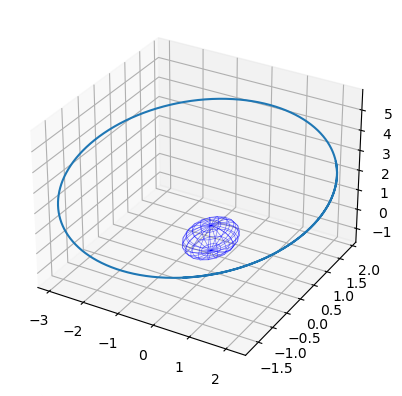

In [7]:
orbit_sim1 = Orbit("Earth")
r = orbit_sim1.dynamics.R
ax = plt.axes(projection='3d')

r0 = [r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r]
    
theta = random.uniform(0, 2 * math.pi)
phi = random.uniform(0, 2 * math.pi)
t = np.linspace(0, 85000, 5000)
    
sol = orbit_sim1.run(r0, theta, phi, t)
A = orbit_sim1.get_attitude(sol)

x = sol[:, 0] / r
y = sol[:, 1] / r
z = sol[:, 2] / r

plt.plot(sol[:, 0], sol[:, 1], sol[:, 2])
        
# Earth
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
ax.plot_wireframe(r*np.cos(u)*np.sin(v),r*np.sin(u)*np.sin(v),
                  r*np.cos(v),color="b",alpha=0.5,lw=0.5,zorder=0)
        
plt.show()

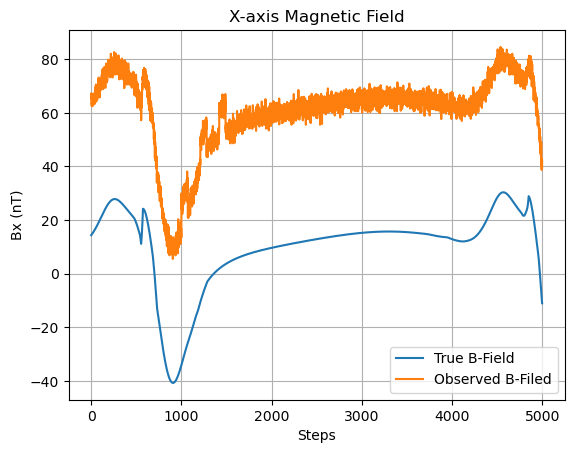

In [9]:
noise_sim = TDNoiseSim()

np.random.seed(42)
N  = 5000
fs = 25.0       # sample rate (Hz)
sigma = 2.0    # Gaussian noise std dev (nT)
t = np.linspace(0, 85000, 5000)

D = [[0.01, -0.005, 0.008], np.deg2rad(1), np.deg2rad(0.8),
      np.deg2rad(0.9), [np.deg2rad(0.5)]*3, np.eye(3)]

b1 = np.array([50., -30., 20.])


noise_sim.set_scaling_matrix(ksi=D[0], rho=D[1],lamb=D[2],phi=D[3],eps=D[4],D_si=D[5])
noise_sim.set_bias(b1)

G = np.array([[1., 0., 0.],
             [0., 1., 0.],
             [0., 0., 1.]])

S = np.array([[0, 0],
             [0, 0],
             [0, 0]])

mtq = np.array([10, -30, 20])

step_signal = np.zeros(N)
step_signal[1000:1070] = 1.0
step_signal[1210:1280] = 1.0
step_signal[1420:1490] = 1.0

ut = 100
xgsm = -5.1
ygsm = 0.3
zgsm = 2.8
ps = -0.533585131 # dipole tilt angle in radians


#1: solar wind dynamic pressure in nPa (typically btwn 0.5 and 3 nPa)
#2: Dst index (measured space weather activity, nT)
#3-4: B component y, z direction of IMF
par = [1., -10., 2., -5., 0., 0., ps, xgsm,ygsm,zgsm]

H_series = np.zeros((N, 3))

X_obs = np.zeros((N, 3))
true_B = np.zeros((N, 3))

for i in range(N):
    ps = geopack.recalc(ut)
    bxgsm,bygsm,bzgsm = t96.t96(par, ps, x[i], y[i], z[i])
    
    H_series[i, 0] = bxgsm
    H_series[i, 1] = bygsm
    H_series[i, 2] = bzgsm
    
    ut = ut + 17
    
    
X_obs, true_B= noise_sim.simulate_orbit(A, H_series, G, S, mtq, sigma, N)

    
plt.plot(range(N), true_B[:, 0], label="True B-Field")
plt.plot(range(N), X_obs[:,0], label="Observed B-Filed")
plt.grid()
plt.xlabel("Steps")
plt.ylabel("Bx (nT)")
plt.title("X-axis Magnetic Field")
plt.legend()
plt.show()


--- UKF Results ---

  Gaussian std: 2.0 nT

  True  B_orbit (last step): [  3.93  -5.9  -30.68]
  Est.  B_orbit (last step): [ -9.26  12.99 -22.31]

  True  B_body  (last step): [-11.03   2.57 -29.38]
  Est.  B_body  (last step): [ -8.62   1.48 -26.  ]


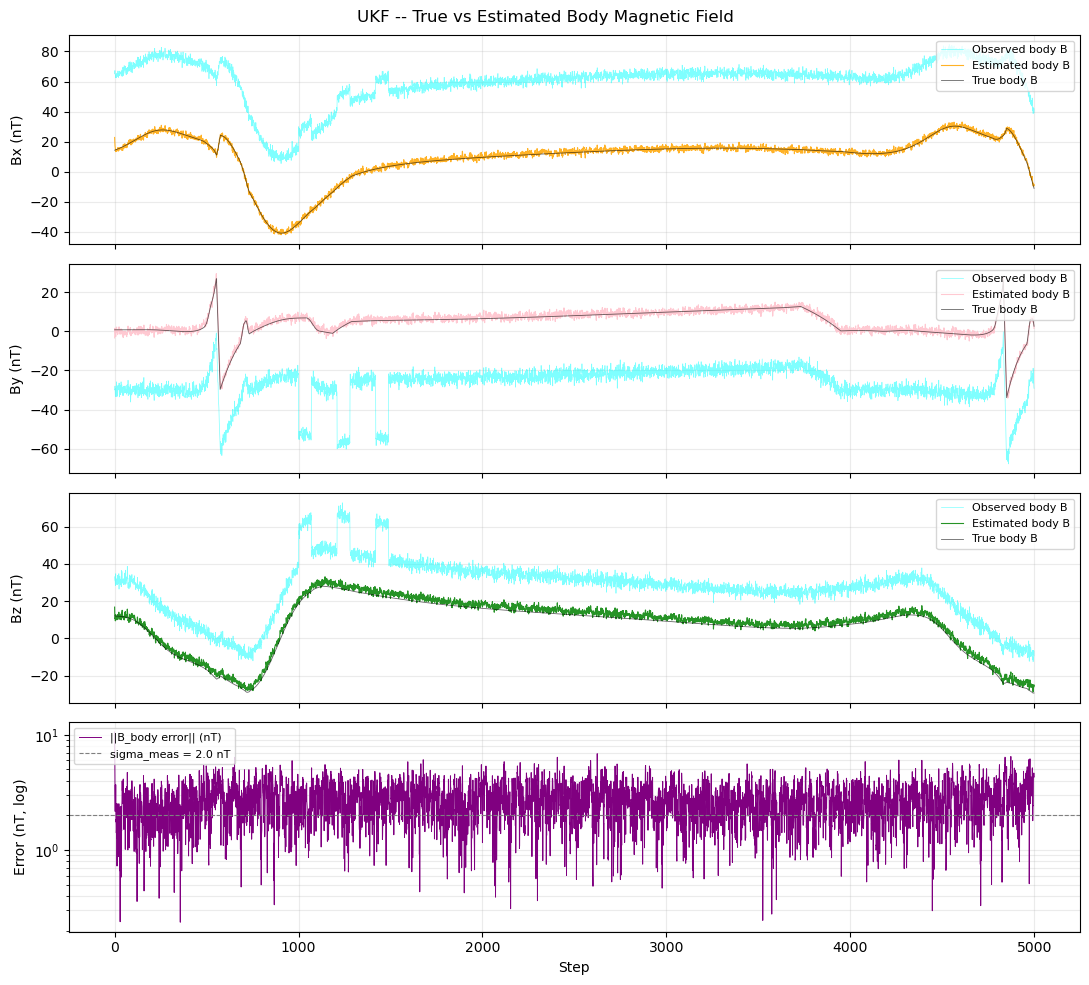

In [10]:
np.random.seed(0)

M = np.outer(mtq.T, step_signal)

D_cal_fixed = np.linalg.inv(noise_sim.D)   
b_cal_fixed = b1.copy()                
G_cal_fixed = G.copy()
M_cal = M.copy() 

sigma_meas = 2.0   # nT, matches sigma in your simulation

B_orbit_seed = X_obs[0].copy()

ukf = UKF(
    D_cal=D_cal_fixed,
    b_cal=b_cal_fixed,
    G_cal=G_cal_fixed,
    M_cal=M_cal[:, 0],
    sigma_meas=sigma_meas,
    sigma_att_walk=2e-3,    # ~0.1 deg/step
    sigma_B_walk=1.5,       # nT/step
    sigma_b_walk=0.01,
)

# start with identity attitude (unknown startup orientation)
ukf.q = np.array([1., 0., 0., 0.])

# fill field state near actual magnitude
ukf.x[3:6] = B_orbit_seed
ukf.P[3:6, 3:6] = np.eye(3) * np.linalg.norm(B_orbit_seed)**2

B_true_hist = np.zeros((N, 3))
B_est_hist  = np.zeros((N, 3))
err_body    = np.zeros(N)

for k in range(N):
    ukf.M_cal=M_cal[:, k]
    ukf.predict()
    B_body_est = ukf.update(X_obs[k])

    B_true_hist[k] = true_B[k]
    B_est_hist[k]  = B_body_est
    err_body[k]    = np.linalg.norm(B_body_est - true_B[k])

print("--- UKF Results ---")
print(f"\n  Gaussian std: {sigma_meas:.1f} nT")
print(f"\n  True  B_orbit (last step): {np.round(H_series[-1], 2)}")
print(f"  Est.  B_orbit (last step): {np.round(ukf.B_orbit_est, 2)}")
print(f"\n  True  B_body  (last step): {np.round(true_B[-1], 2)}")
print(f"  Est.  B_body  (last step): {np.round(B_body_est, 2)}")

# Plot
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
labels = ['Bx', 'By', 'Bz']
colors = ['orange', 'pink', 'green']
for i, (ax, lbl, col) in enumerate(zip(axes[:3], labels, colors)):
    ax.plot(X_obs[:, i],       color='cyan', lw=0.5, alpha=0.5,  label='Observed body B')
    ax.plot(B_est_hist[:, i],  color=col,    lw=0.8, alpha=0.85, label='Estimated body B')
    ax.plot(B_true_hist[:, i], color='k',    lw=0.6, alpha=0.6,  label='True body B')
    ax.set_ylabel(f'{lbl} (nT)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.25)

axes[3].semilogy(err_body + 1e-3, color='purple', lw=0.7, label='||B_body error|| (nT)')
axes[3].axhline(sigma_meas, color='gray', ls='--', lw=0.8,
                label=f'sigma_meas = {sigma_meas} nT')
axes[3].set_ylabel('Error (nT, log)')
axes[3].set_xlabel('Step')
axes[3].legend(fontsize=8)
axes[3].grid(True, alpha=0.25, which='both')
plt.suptitle('UKF -- True vs Estimated Body Magnetic Field', fontsize=12)
plt.tight_layout()
plt.show()


### 3) Real Data

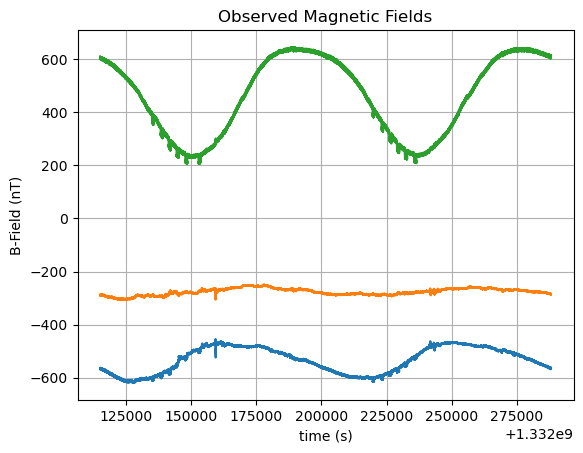

In [12]:
df_space = pd.read_csv('20120319.dat', sep=r'\s+', header=None)
df_space2 = pd.read_csv('20120320.dat', sep=r'\s+', header=None)

mag = df_space.to_numpy()
mag2 = df_space2.to_numpy()

mag = np.vstack((mag, mag2))

t = mag[:, 0]
X_obs = mag[:, 7:10]
X_obs = X_obs

plt.plot(t, X_obs)
plt.grid()
plt.xlabel("time (s)")
plt.ylabel("B-Field (nT)")
plt.title("Observed Magnetic Fields")
plt.show()

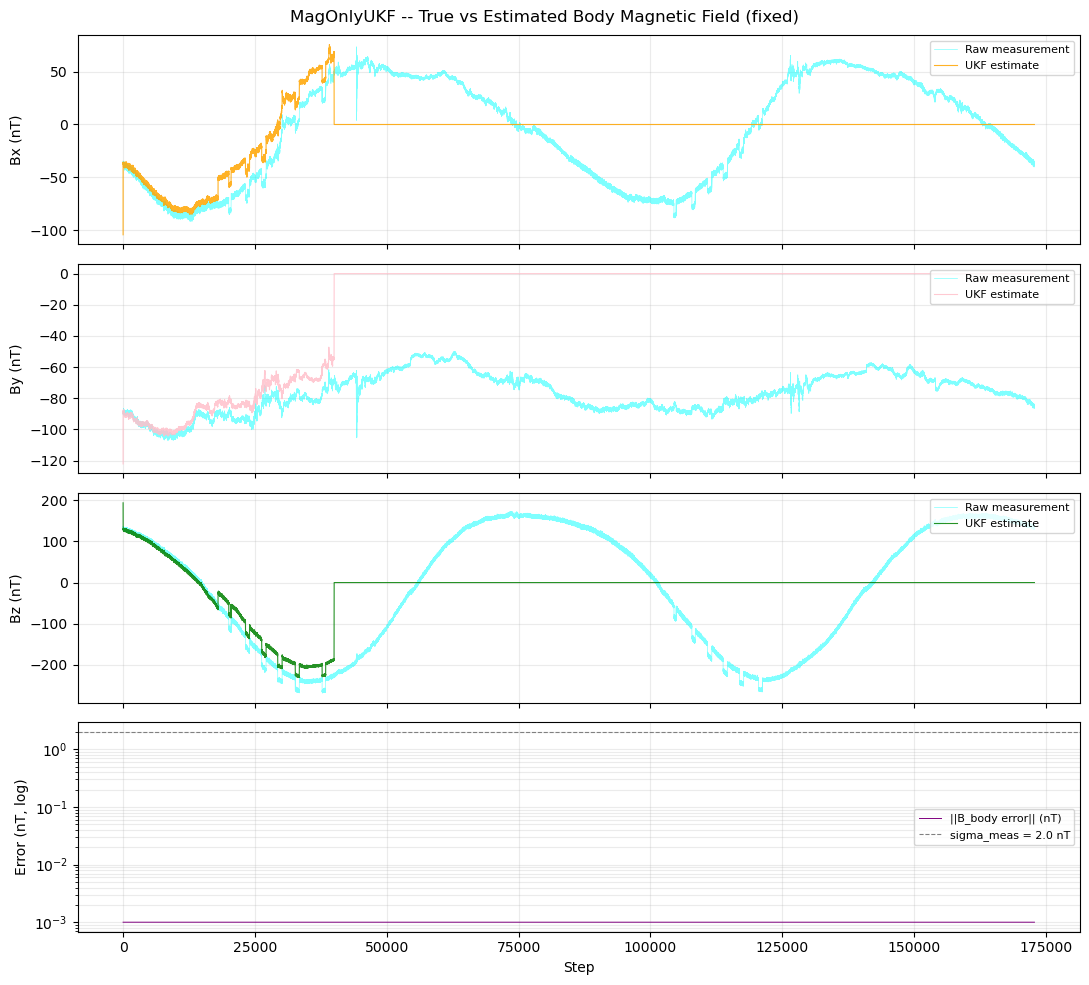

In [13]:
np.random.seed(0)

step_signal = np.zeros(len(t))
step_signal[18000:40000] = 1.0

mtq = np.array([-20, 0, -40])

M = np.outer(mtq.T, step_signal)

G = np.eye(3)

A_cal_fixed = np.linalg.inv(np.eye(3))
b_cal_fixed = np.array([-528, -200, 474])
G_cal_fixed = G
M_cal_fixed = M

sigma_meas = 2.0   # nT, matches sigma in your simulation

B_orbit_seed = X_obs[0, :].copy()

ukf = UKF(
    D_cal=D_cal_fixed,
    b_cal=b_cal_fixed,
    G_cal=G_cal_fixed,
    M_cal=M_cal_fixed[:, 0],
    sigma_meas=sigma_meas,
    sigma_att_walk=2e-3,    # ~0.1 deg/step
    sigma_B_walk=1.5,       # nT/step
    sigma_b_walk=0.01,
)

# start with identity attitude (unknown startup orientation)
ukf.q = np.array([1., 0., 0., 0.])

# fill field state near actual magnitude
ukf.x[3:6] = B_orbit_seed
ukf.P[3:6, 3:6] = np.eye(3) * np.linalg.norm(B_orbit_seed)**2

N = len(X_obs[:, 0])

B_est_hist  = np.zeros((N, 3))
err_body    = np.zeros(N)

for k in range(40000):
    ukf.M_cal=M_cal_fixed[:,k]
    ukf.predict()
    B_body_est = ukf.update(X_obs[k])
    B_est_hist[k]  = B_body_est

# Plot
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
labels = ['Bx', 'By', 'Bz']
colors = ['orange', 'pink', 'green']
for i, (ax, lbl, col) in enumerate(zip(axes[:3], labels, colors)):
    ax.plot(X_obs[:, i] - b_cal_fixed[i],       color='cyan', lw=0.5, alpha=0.5,  label='Raw measurement')
    ax.plot(B_est_hist[:, i],  color=col,    lw=0.8, alpha=0.85, label='UKF estimate')
    ax.set_ylabel(f'{lbl} (nT)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.25)

axes[3].semilogy(err_body + 1e-3, color='purple', lw=0.7, label='||B_body error|| (nT)')
axes[3].axhline(sigma_meas, color='gray', ls='--', lw=0.8,
                label=f'sigma_meas = {sigma_meas} nT')
axes[3].set_ylabel('Error (nT, log)')
axes[3].set_xlabel('Step')
axes[3].legend(fontsize=8)
axes[3].grid(True, alpha=0.25, which='both')
plt.suptitle('MagOnlyUKF -- True vs Estimated Body Magnetic Field (fixed)', fontsize=12)
plt.tight_layout()
plt.show()


notes: if I have time, could write code that manually finds when the step functions / stray noise are so I don't need to rely on knowing ahead of time... use ICA peak-finding code?